# CSCI 3003 Exam 1 Part 2 Practical

**Name:** ___________Steve Tatsiguia_________________________  **Date:** ______10/06/2026______________

**Time target:** 45 minutes  
**Points:** 60 points plus 5 possible extra-credit points

Complete this notebook independently. You may use your prior course notebooks and Python or library documentation accessed inside VS Code. Other websites and online resources are not permitted, including through VS Code. Do not use generative AI, communicate with other people, or access the internet outside VS Code.

## Submission

Before submitting:

- Restart the kernel and run all cells from top to bottom.
- Read any error messages and correct your work.
- Inspect every graph for a useful title and labeled axes.
- Export the completed notebook to HTML.
- Submit the completed HTML file in Canvas.

## Dataset

The file `bike_sharing_exam.csv` contains daily Capital Bikeshare rental counts from Washington, DC, during 2011 and 2012, together with calendar and weather information. One row represents one day.

| Column | Values or units |
|---|---|
| `date` | Calendar date |
| `year` | 2011 or 2012 |
| `season` | Spring, Summer, Fall, or Winter |
| `weather` | Daily weather category |
| `day_type` | Working day or weekend/holiday |
| `temperature_c` | Normalized daily temperature converted to degrees Celsius |
| `feels_like_c` | Normalized perceived temperature converted to degrees Celsius |
| `humidity_percent` | Relative humidity percentage |
| `wind_speed` | Normalized wind speed converted using the source scale |
| `casual_rentals` | Daily rentals by casual users |
| `registered_rentals` | Daily rentals by registered users |
| `total_rentals` | Total daily rentals |

Source: Hadi Fanaee-T, *Bike Sharing* (2013), UCI Machine Learning Repository, https://doi.org/10.24432/C5W894. Licensed CC BY 4.0. Accessed September 26, 2026. This exam file renames categorical values and converts normalized weather variables to readable scales.

## Setup

Keep this notebook and `bike_sharing_exam.csv` together in the same folder. The Jupyter kernel's working directory must be that folder; relative file paths are resolved from the working directory. Run the setup cells and confirm that the displayed directory is the folder containing both files and that the file check prints `True`. If it prints `False`, confirm the CSV's exact filename in the VS Code Explorer and ask the instructor for help correcting the working directory before continuing. Opening a folder in the Explorer does not necessarily set the kernel's working directory.

In [34]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [35]:
working_directory = Path.cwd()
working_directory

WindowsPath('c:/Users/steve/OneDrive/Documents/CSCI-3003-Data-Visualization/02-exams')

In [36]:
data_file = Path("bike_sharing_exam.csv")
print("Data file found:", data_file.exists())

Data file found: True


## Data profiling

**Question 1 (8 points):** Load `bike_sharing_exam.csv` into a DataFrame named `bikes`. Profile the data with commands that show the first rows, number of rows and columns, column names and data types, and the number of missing values in each column. Then state what one row represents and identify one qualitative and one quantitative variable.

**Answer:** One row represents one day of Bikeshare rentals. season is a qualitative variable because it identifies categories. total_rentals is a quantitative variable because it records the number of rentals that day.



In [37]:
bikes = pd.read_csv(data_file)

display(bikes.head())          # First five rows
display("Columns and rows: {}".format(bikes.shape))
display(bikes.info())          # Column names and data types
display(bikes.isna().sum())    # Missing values per column

,date,year,season,weather,day_type,temperature_c,feels_like_c,humidity_percent,wind_speed,casual_rentals,registered_rentals,total_rentals
0,2011-01-01,2011,Spring,Misty or cloudy,Weekend or holiday,14.1,18.2,80.6,10.7,331,654,985
1,2011-01-02,2011,Spring,Misty or cloudy,Weekend or holiday,14.9,17.7,69.6,16.7,131,670,801
2,2011-01-03,2011,Spring,Clear or partly cloudy,Working day,8.1,9.5,43.7,16.6,120,1229,1349
3,2011-01-04,2011,Spring,Clear or partly cloudy,Working day,8.2,10.6,59.0,10.7,108,1454,1562
4,2011-01-05,2011,Spring,Clear or partly cloudy,Working day,9.3,11.5,43.7,12.5,82,1518,1600


'Columns and rows: (731, 12)'

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                731 non-null    str    
 1   year                731 non-null    int64  
 2   season              731 non-null    str    
 3   weather             731 non-null    str    
 4   day_type            731 non-null    str    
 5   temperature_c       731 non-null    float64
 6   feels_like_c        731 non-null    float64
 7   humidity_percent    731 non-null    float64
 8   wind_speed          728 non-null    float64
 9   casual_rentals      731 non-null    int64  
 10  registered_rentals  731 non-null    int64  
 11  total_rentals       731 non-null    int64  
dtypes: float64(4), int64(4), str(4)
memory usage: 68.7 KB


None

date                  0
year                  0
season                0
weather               0
day_type              0
temperature_c         0
feels_like_c          0
humidity_percent      0
wind_speed            3
casual_rentals        0
registered_rentals    0
total_rentals         0
dtype: int64

## One categorical variable

**Question 2 (7 points):** Show the distribution of `season`. Create a frequency table and the appropriate labeled graph. Describe the largest and smallest categories.

**Answer:** The largest category is fall with 188 days, and the smallest category is winter with 178 days. A bar chart compares the frequency of each season.



season
Fall      188
Summer    184
Spring    181
Winter    178
Name: count, dtype: int64

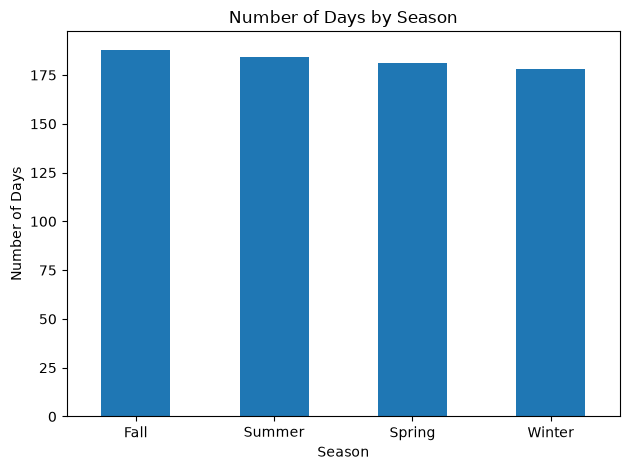

Largest categories:


season
Fall    188
Name: count, dtype: int64

Smallest categories:


season
Winter    178
Name: count, dtype: int64

In [38]:
season_counts = bikes["season"].value_counts()
display(season_counts)

season_counts.plot(kind="bar")
plt.title("Number of Days by Season")
plt.xlabel("Season")
plt.ylabel("Number of Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Largest categories:")
display(season_counts[season_counts == season_counts.max()])

print("Smallest categories:")
display(season_counts[season_counts == season_counts.min()])

## Two categorical variables

**Question 3 (8 points):** Compare `season` and `day_type`. Create a two-way frequency table using counts and a labeled grouped bar chart. Describe one pattern shown by the table or graph.

**Answer:** Working days are more frequent than weekend or holiday days in every season.



day_type,Weekend or holiday,Working day
season,,
Fall,57,131
Spring,61,120
Summer,56,128
Winter,57,121


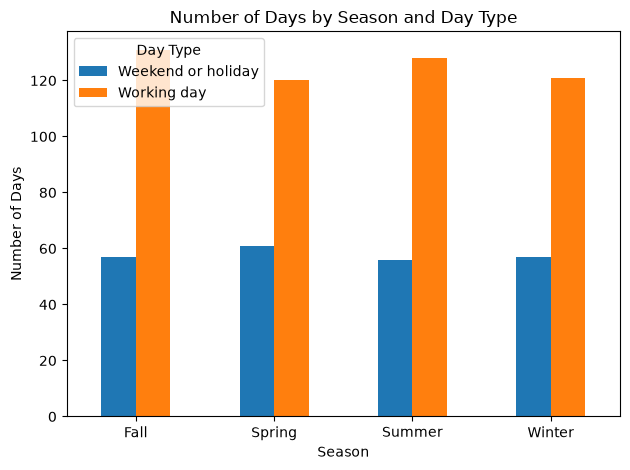

In [39]:
season_day_counts = pd.crosstab(bikes["season"], bikes["day_type"]) # Create a cross-tabulation of season and day_type
display(season_day_counts)

season_day_counts.plot(kind="bar", stacked=False) # Create a bar plot of the cross-tabulation
plt.title("Number of Days by Season and Day Type")
plt.xlabel("Season")
plt.ylabel("Number of Days")
plt.xticks(rotation=0) 
plt.legend(title="Day Type")
plt.tight_layout()
plt.show()

## One quantitative variable

**Question 4 (7 points):** Show the distribution of `total_rentals` with the most appropriate graph for examining its shape. Try at least two reasonable bin counts and retain the clearer version. In your written response, state the bin counts you tried and briefly justify your final choice; only the final graph needs to remain in the notebook.

**Answer:** I tried 15 and 30 bins and retained 15 bins because it shows the overall shape of daily rental counts clearly without splitting the data into too many small intervals.



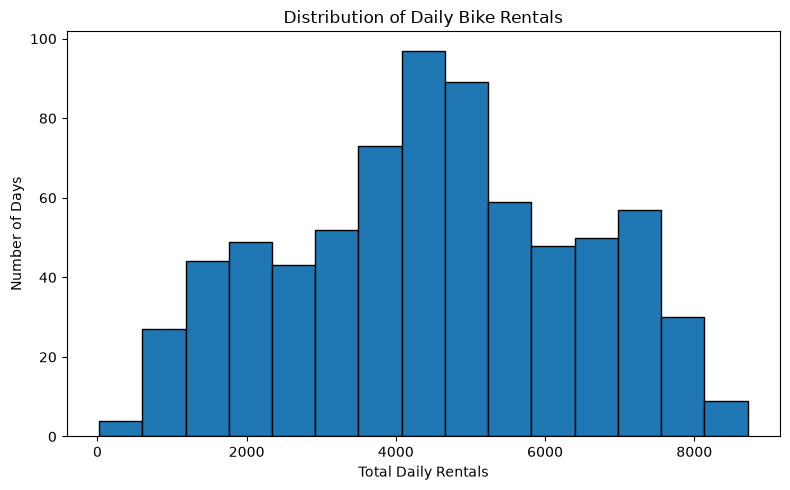

In [40]:
plt.figure(figsize=(8, 5)) # Set the figure size for the histogram
plt.hist(bikes["total_rentals"].dropna(), bins=15, edgecolor="black") # Create a histogram of total daily rentals, dropping any missing values
plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Total Daily Rentals")
plt.ylabel("Number of Days")
plt.tight_layout() # Adjust the layout to prevent overlap
plt.show()

## Two quantitative variables

**Question 5 (7 points):** Show the relationship between `temperature_c` and `total_rentals` with an appropriate labeled graph. Describe the direction, form, and strength appropriately.

**Answer:** Temperature and total daily rentals show a moderately strong positive relationship: warmer days generally have more rentals. The pattern is roughly linear overall, although rentals appear to level off or decrease at the highest temperatures. There is considerable scatter, so temperature alone does not fully explain daily rental counts.



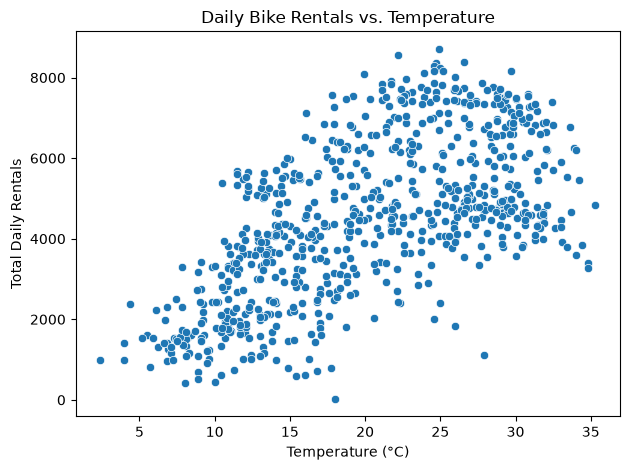

In [41]:
sns.scatterplot(data=bikes, x="temperature_c", y="total_rentals") # Create a scatter plot of temperature vs. total daily rentals
plt.title("Daily Bike Rentals vs. Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Total Daily Rentals")
plt.tight_layout()
plt.show()

## A quantitative variable across categories

**Question 6 (7 points):** Compare the distribution of `total_rentals` across `season` with an appropriate labeled Seaborn graph. Identify the group with the highest median and describe one feature of the within-group variation.

**Answer:** Fall has the highest median, at approximately 5,000 rentals per day. Fall also shows substantial within-group variation: the middle 50% of daily rental counts ranges from about 4,500 to 6,500 rentals.



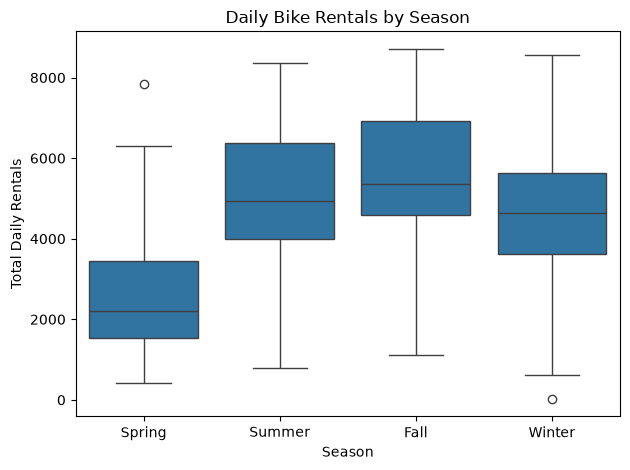

In [42]:
sns.boxplot(data=bikes, x="season", y="total_rentals")
plt.title("Daily Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Total Daily Rentals")
plt.tight_layout()
plt.show()

## Simple linear regression

**Question 7 (16 points):** Use `temperature_c` to explain variation in `total_rentals` with `LinearRegression`.

A. Select the data needed for this analysis, removing NA values.

B. Create and fit the model. Report the fitted equation and interpret the slope in context.

C. Display the relationship between `temperature_c` and `total_rentals` using a scatterplot with the fitted regression line overlaid. 

D. Calculate/display the R-squared. Interpret the R-squared value.

E. Generate fitted values for the observed rows. Create a residual-versus-fitted scatterplot with a horizontal reference line at zero. Describe one pattern or limitation you see.

**Answer:** After removing rows with missing temperature or rental values, the fitted equation is:
Predicted daily rentals = 1,214.97 + 161.95 × temperature (°C).
Each 1°C increase in temperature is associated with approximately 162 additional predicted daily rentals.
The R-squared is 0.394, meaning this model explains approximately 39.4% of the variation in daily rental counts.
The residuals show a curved pattern: they tend to be negative at low and high fitted values and positive in the middle. This suggests that a straight line does not fully capture the relationship between temperature and rentals.
 


In [43]:
# A. Select data for analysis
regression_data = bikes[["temperature_c", "total_rentals"]].dropna() # Drop rows with missing values in either column

X = regression_data[["temperature_c"]]
y = regression_data["total_rentals"]

In [44]:
# B. Create and fit the model.
model = LinearRegression()
model.fit(X, y)

intercept = model.intercept_ # Get the intercept (b0) of the regression line
slope = model.coef_[0] # Get the slope (b1) of the regression line

print(f"Predicted total rentals = {intercept:.2f} + {slope:.2f} × temperature_c")
print(f"Each 1°C increase is associated with {slope:.2f} more predicted daily rentals.")

Predicted total rentals = 1214.97 + 161.95 × temperature_c
Each 1°C increase is associated with 161.95 more predicted daily rentals.


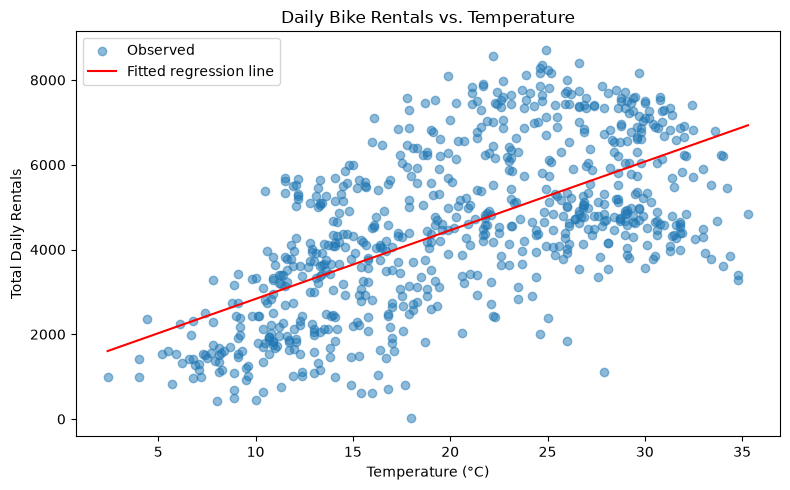

In [45]:
# C. Plot relationship
fitted_values = model.predict(X) 
plot_data = regression_data.assign(fitted=fitted_values)
plot_data = plot_data.sort_values("temperature_c")

plt.figure(figsize=(8, 5))
plt.scatter(X["temperature_c"], y, alpha=0.5, label="Observed")
plt.plot(
    plot_data["temperature_c"],
    plot_data["fitted"],
    color="red",
    label="Fitted regression line"
)
plt.title("Daily Bike Rentals vs. Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Total Daily Rentals")
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
# D. R-Squared
r_squared = r2_score(y, fitted_values) # Calculate R-squared
print(f"R-squared: {r_squared:.3f}")
print(f"The model explains {r_squared:.1%} of the variation in daily rentals.")

R-squared: 0.394
The model explains 39.4% of the variation in daily rentals.


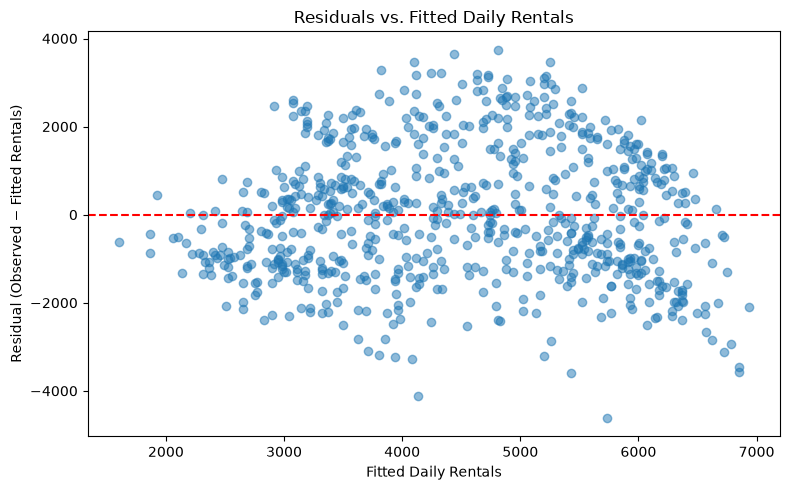

In [47]:
# E. Create residuals and the diagnostic graph.
residuals = y - fitted_values

plt.figure(figsize=(8, 5))
plt.scatter(fitted_values, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs. Fitted Daily Rentals")
plt.xlabel("Fitted Daily Rentals")
plt.ylabel("Residual (Observed − Fitted Rentals)")
plt.tight_layout()
plt.show()

## Extra credit independent analysis

**Question 8 (up to 5 extra-credit points):** Pose one defensible question about this dataset that is not identical to Questions 2-7. Select suitable variables, prepare the needed data, create a labeled visualization, interpret the evidence, and state one limitation.

**Answer:** How did daily bike rentals differ between 2011 and 2012? This compares rentals across years, which differs from previous analyses.



year
2011    3740.0
2012    5927.0
Name: total_rentals, dtype: float64

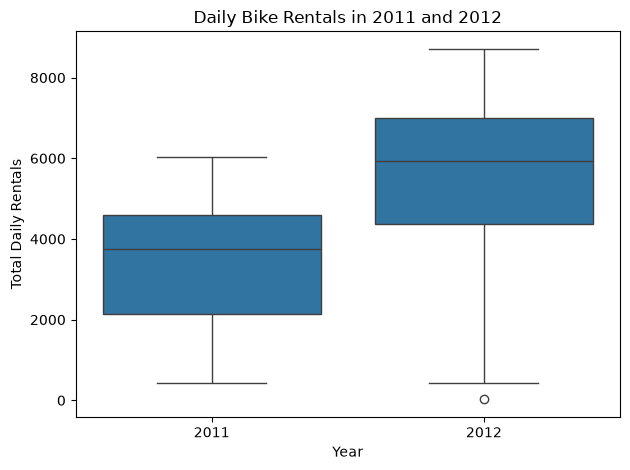

In [48]:
year_data = bikes[["year", "total_rentals"]].dropna() # Drop rows with missing values in either column

display(year_data.groupby("year")["total_rentals"].median()) # Display median rentals by year

sns.boxplot(data=year_data, x="year", y="total_rentals") # Create boxplot
plt.title("Daily Bike Rentals in 2011 and 2012")
plt.xlabel("Year")
plt.ylabel("Total Daily Rentals")
plt.tight_layout()
plt.show()

## Final submission check

- Every required code cell runs without an error.
- Every written response is complete.
- Every graph has a useful title and labeled axes.
- The HTML export shows all code, output, graphs, and responses.